# Honduras rainfall from CHIRPS (Google Earth Engine)
**CLMT G5047 · ENSO Exposure Project · Rainfall stream**

This notebook pulls CHIRPS **pentad** (5-day) rainfall for all 18 departments of Honduras plus the national mean, 1981 to the latest available pentad, and turns it into:

| Output (saved to Drive › `ENSO_project`) | What it is |
|---|---|
| `hnd_rain_pentad.csv` | Tidy pentad rainfall, one row per department × pentad |
| `hnd_rain_monthly.csv` | Monthly totals (incomplete months set to blank) |
| `hnd_rain_seasonal.csv` | Per department-year: primera (May–Aug) total, Jul–Aug (canícula) total, dry pentads, longest dry run, anomalies vs 1991–2020 |
| `fig_rain_timeseries.png` | Draft time-series figure, El Niño years marked |
| `fig_rain_comparison.png` | Draft comparison figure: 1997, 2015, 2023, 2026 vs climatology |
| `fig_rain_map.png` | Draft map figure: canícula anomaly by department |

**AI attribution (for the rubric):** every code cell starts with an `AI-generated` header.

## 1 · Connect to Earth Engine and Google Drive

In [1]:
# Written by: Claude (Anthropic), 25 Oct 2026, chat conversation. Reviewed by: Fabricio Correa Lara
# What I checked: ("18 departments printed, names correct")
# What I changed: (none yet)
import ee, json, time, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

PROJECT_ID = 'enso-honduras'   # <- from step 0.3

ee.Authenticate()                  # opens a sign-in prompt the first time
ee.Initialize(project=PROJECT_ID)
drive.mount('/content/drive')
print('Earth Engine and Drive connected.')

Mounted at /content/drive
Earth Engine and Drive connected.


In [2]:
# Written by: Claude (Anthropic), 25 Oct 2026, chat conversation Reviewed by: Fabricio Correa Lara
# What I checked: (e.g. "values match my yield worksheet")
# What I changed: (none yet)
COUNTRY_ISO3   = 'HND'
START, END     = '1981-01-01', '2027-01-01'
BASELINE       = (1991, 2020)      # WMO standard normal; same as the brief's example
PRIMERA_MONTHS = [5, 6, 7, 8]      # planting (May-Jun) through canícula (Jul-Aug)
CANICULA_MONTHS = [7, 8]           # midsummer drought window
DRY_PENTAD_MM  = 10.0              # a pentad below 10 mm (~2 mm/day) counts as dry; also try 5 and 15
EVENT_YEARS    = [1997, 2015, 2023, 2026]
MAP_YEARS      = [1997, 2015, 2026]
MAP_METRIC     = 'canicula_mm_anom_pct'   # or 'primera_mm_anom_pct'

# Dry Corridor: list department names FROM A SOURCE YOU WILL CITE (e.g. a FAO or FEWS NET
# Dry Corridor map). Leave empty to use the national mean in the figures.
# Accents and capitals don't matter: 'el paraiso' matches 'El Paraíso'.
DRY_CORRIDOR   = []

DRIVE_FOLDER = 'ENSO_project'
OUT_DIR      = f'/content/drive/MyDrive/{DRIVE_FOLDER}'
GEOJSON_PATH = f'{OUT_DIR}/hnd_departments.geojson'

## 3 · Department boundaries and CHIRPS version
Boundaries come from **FAO GAUL 2025 (level 1)**, with geoBoundaries v6 as a fallback. The cell also saves a simplified copy for the map figure.

CHIRPS exists in two versions in Earth Engine. Use **one version for the whole series**; never mix them. The cell prefers v3 (the current release) if it already covers the 2026 primera, otherwise v2.

In [3]:
# Written by: Claude (Anthropic), 25 Oct 2026, chat conversation # Reviewed by: Fabricio Correa Lara
# What I checked: (e.g. "values match my yield worksheet")
# What I changed: (none yet)
import os
os.makedirs(OUT_DIR, exist_ok=True)

# --- Boundaries -----------------------------------------------------------
adm1 = ee.FeatureCollection('FAO/GAUL/2025/level1').filter(ee.Filter.eq('ISO3_CODE', COUNTRY_ISO3))
BOUNDARY_SOURCE = 'FAO GAUL 2025, level 1'
if adm1.size().getInfo() == 0:
    adm1 = (ee.FeatureCollection('WM/geoLab/geoBoundaries/600/ADM1')
              .filter(ee.Filter.eq('shapeGroup', COUNTRY_ISO3))
              .map(lambda f: f.set('GAUL1_NAME', f.get('shapeName'))))
    BOUNDARY_SOURCE = 'geoBoundaries v6.0.0, ADM1'

depts = adm1.map(lambda f: ee.Feature(f.geometry(), {
    'dept': f.get('GAUL1_NAME'),
    'area_km2': f.geometry().area(100).divide(1e6)}))
national_geom = adm1.geometry().dissolve(100)
national = ee.Feature(national_geom, {'dept': 'HONDURAS_NATIONAL',
                                      'area_km2': national_geom.area(100).divide(1e6)})
regions = depts.merge(ee.FeatureCollection([national]))

names = sorted(depts.aggregate_array('dept').getInfo())
print(f'{BOUNDARY_SOURCE}: {len(names)} departments')
print(names)
if len(names) != 18:
    print('WARNING: Honduras has 18 departments; check the boundary layer before going on.')

# Simplified geometries for the map (small enough to download directly)
gj = depts.map(lambda f: f.simplify(500)).getInfo()
with open(GEOJSON_PATH, 'w') as fh:
    json.dump(gj, fh)
print('Saved', GEOJSON_PATH)

# --- CHIRPS version -------------------------------------------------------
CANDIDATES = {'v3': 'UCSB-CHC/CHIRPS/V3/PENTAD', 'v2': 'UCSB-CHG/CHIRPS/PENTAD'}
coverage = {}
for v, cid in CANDIDATES.items():
    col = ee.ImageCollection(cid)
    first = ee.Date(col.aggregate_min('system:time_start')).format('YYYY-MM-dd').getInfo()
    last = ee.Date(col.aggregate_max('system:time_start')).format('YYYY-MM-dd').getInfo()
    coverage[v] = (first, last)
    print(f'CHIRPS {v}: {first} to {last} (start date of last pentad)')

NEED_LAST = '2026-08-26'           # first day of the last August pentad
if coverage['v3'][1] >= NEED_LAST:
    CHIRPS_VERSION = 'v3'
elif coverage['v2'][1] >= NEED_LAST:
    CHIRPS_VERSION = 'v2'
else:
    CHIRPS_VERSION = 'v3'
    print('NOTE: neither version covers Jul-Aug 2026 yet; 2026 will show as incomplete. '
          'Record this as a data problem for Milestone 1.')
CHIRPS_ID = CANDIDATES[CHIRPS_VERSION]
print('Using CHIRPS', CHIRPS_VERSION, '->', CHIRPS_ID)

FAO GAUL 2025, level 1: 18 departments
['Atlantida', 'Choluteca', 'Colon', 'Comayagua', 'Copan', 'Cortes', 'El Paraiso', 'Francisco Morazan', 'Gracias A Dios', 'Intibuca', 'Islas De La Bahia', 'La Paz', 'Lempira', 'Ocotepeque', 'Olancho', 'Santa Barbara', 'Valle', 'Yoro']
Saved /content/drive/MyDrive/ENSO_project/hnd_departments.geojson
CHIRPS v3: 1981-01-01 to 2026-09-26 (start date of last pentad)
CHIRPS v2: 1981-01-01 to 2026-09-26 (start date of last pentad)
Using CHIRPS v3 -> UCSB-CHC/CHIRPS/V3/PENTAD


## 4. Start the extraction (runs on Google's servers)
For each pentad image the cell averages rainfall over every department and over the whole country, then exports one CSV (about 60,000 rows) to Drive. Expect it to take several minutes or more.

In [7]:

EXPORT_NAME = f'hnd_chirps_{CHIRPS_VERSION}_pentad_raw'

chirps = ee.ImageCollection(CHIRPS_ID).filterDate(START, END).select('precipitation')

def per_image(img):
    stats = img.reduceRegions(collection=regions, reducer=ee.Reducer.mean(),
                              scale=5566, tileScale=2)
    def clean(f):
        return ee.Feature(None, {
            'dept': f.get('dept'),
            'precip_mm': f.get('mean'),     # area-mean rainfall, mm per pentad
            'date': img.date().format('YYYY-MM-dd'),
            'year': img.get('year'), 'month': img.get('month'), 'pentad': img.get('pentad')})
    return stats.map(clean)

table = chirps.map(per_image).flatten()

task = ee.batch.Export.table.toDrive(
    collection=table, description=EXPORT_NAME, folder=DRIVE_FOLDER,
    fileNamePrefix=EXPORT_NAME, fileFormat='CSV',
    selectors=['dept', 'date', 'year', 'month', 'pentad', 'precip_mm'])
task.start()
print('Export started:', EXPORT_NAME, '| images:', chirps.size().getInfo())

Export started: hnd_chirps_v3_pentad_raw | images: 3294


In [8]:

# Check on the export. Re-run this cell, or watch https://code.earthengine.google.com/tasks
while task.active():
    print(time.strftime('%H:%M:%S'), task.status()['state'])
    time.sleep(60)
status = task.status()
print(status['state'], status.get('error_message', ''))

22:40:16 RUNNING
22:41:17 RUNNING
22:42:17 RUNNING
22:43:17 RUNNING
22:44:18 RUNNING
22:45:18 RUNNING
22:46:18 RUNNING
22:47:18 RUNNING
22:48:19 RUNNING
22:49:19 RUNNING
22:50:29 RUNNING
22:51:29 RUNNING
22:52:30 RUNNING
22:53:30 RUNNING
22:54:30 RUNNING
22:55:31 RUNNING
22:56:31 RUNNING
22:57:31 RUNNING
22:58:32 RUNNING
22:59:32 RUNNING
23:00:32 RUNNING
23:01:32 RUNNING


23:02:33 RUNNING
23:03:33 RUNNING
23:04:34 RUNNING
23:05:34 RUNNING
23:06:34 RUNNING
23:07:35 RUNNING
23:08:35 RUNNING
23:09:35 RUNNING
23:10:36 RUNNING
23:11:36 RUNNING
23:12:36 RUNNING
23:13:37 RUNNING
23:14:37 RUNNING
23:15:37 RUNNING
23:16:37 RUNNING
23:17:38 RUNNING
23:18:38 RUNNING
23:19:38 RUNNING
23:20:39 RUNNING
23:21:39 RUNNING
23:22:39 RUNNING
23:23:39 RUNNING
23:24:40 RUNNING
23:25:40 RUNNING
23:26:40 RUNNING
23:27:41 RUNNING
23:28:41 RUNNING
23:29:41 RUNNING
23:30:42 RUNNING
23:31:42 RUNNING
23:32:42 RUNNING
23:33:43 RUNNING
23:34:43 RUNNING
23:35:43 RUNNING
23:36:44 RUNNING
23:37:44 RUNNING
23:38:44 RUNNING
23:39:45 RUNNING
23:40:45 RUNNING
23:41:45 RUNNING
23:42:46 RUNNING
23:43:46 RUNNING
23:44:46 RUNNING
23:45:47 RUNNING
23:46:47 RUNNING
23:47:47 RUNNING
23:48:48 RUNNING
23:49:48 RUNNING
23:50:48 RUNNING
23:51:48 RUNNING
23:52:49 RUNNING
23:53:49 RUNNING
23:54:49 RUNNING
23:55:50 RUNNING
23:56:50 RUNNING
23:57:50 RUNNING


23:58:51 RUNNING
23:59:51 RUNNING
00:00:52 RUNNING
00:01:52 RUNNING
00:02:52 RUNNING
00:03:53 RUNNING
00:04:53 RUNNING
00:05:53 RUNNING
00:06:54 RUNNING
00:07:54 RUNNING
00:08:54 RUNNING
00:09:55 RUNNING
00:10:55 RUNNING
00:11:55 RUNNING
00:12:55 RUNNING
00:13:56 RUNNING
00:14:56 RUNNING
00:15:56 RUNNING
00:16:57 RUNNING
00:17:57 RUNNING
00:18:57 RUNNING
00:19:57 RUNNING
00:20:58 RUNNING
00:21:58 RUNNING
00:22:58 RUNNING
00:23:59 RUNNING
00:24:59 RUNNING
00:25:59 RUNNING
00:27:00 RUNNING
00:28:00 RUNNING
00:29:00 RUNNING
00:30:01 RUNNING
00:31:01 RUNNING
00:32:01 RUNNING
00:33:01 RUNNING
00:34:02 RUNNING
00:35:02 RUNNING
00:36:03 RUNNING
00:37:03 RUNNING
00:38:03 RUNNING
00:39:04 RUNNING
00:40:04 RUNNING
00:41:04 RUNNING
00:42:05 RUNNING
00:43:05 RUNNING
00:44:05 RUNNING
00:45:06 RUNNING
00:46:06 RUNNING
00:47:06 RUNNING
00:48:07 RUNNING
00:49:07 RUNNING
00:50:08 RUNNING
00:51:08 RUNNING
00:52:08 RUNNING
00:53:09 RUNNING
00:54:09 RUNNING


00:55:10 RUNNING
00:56:10 RUNNING
00:57:10 RUNNING
00:58:10 RUNNING
00:59:11 RUNNING
01:00:11 RUNNING
01:01:11 RUNNING
01:02:12 RUNNING
01:03:12 RUNNING
01:04:12 RUNNING
01:05:12 RUNNING
01:06:13 RUNNING
01:07:13 RUNNING
01:08:13 RUNNING
01:09:14 RUNNING
01:10:14 RUNNING
01:11:14 RUNNING
01:12:15 RUNNING
01:13:15 RUNNING
01:14:15 RUNNING
01:15:16 RUNNING
01:16:16 RUNNING
01:17:16 RUNNING
01:18:16 RUNNING
01:19:17 RUNNING
01:20:17 RUNNING
01:21:17 RUNNING
01:22:18 RUNNING
01:23:18 RUNNING
01:24:18 RUNNING
01:25:19 RUNNING
01:26:19 RUNNING
01:27:19 RUNNING
01:28:20 RUNNING
01:29:20 RUNNING
01:30:20 RUNNING
01:31:21 RUNNING
01:32:21 RUNNING
01:33:21 RUNNING
01:34:21 RUNNING
01:35:22 RUNNING
01:36:22 RUNNING
01:37:22 RUNNING
01:38:23 RUNNING
01:39:23 RUNNING
01:40:23 RUNNING
01:41:24 RUNNING
01:42:24 RUNNING
01:43:25 RUNNING
01:44:25 RUNNING
01:45:25 RUNNING
01:46:26 RUNNING
01:47:26 RUNNING


KeyboardInterrupt: 

In [4]:
# AI-generated: Claude
EXPORT_NAME = 'hnd_chirps_v3_pentad_raw'

## 5 · Load and tidy

In [5]:

raw = pd.read_csv(f'{OUT_DIR}/{EXPORT_NAME}.csv')

def norm(s):
    return unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().lower().strip()

df = raw.copy()
df['date'] = pd.to_datetime(df['date'])
df['precip_mm'] = pd.to_numeric(df['precip_mm'], errors='coerce')
for c in ['year', 'month', 'pentad']:
    df[c] = df[c].astype(int)
df['pentad_of_year'] = (df['month'] - 1) * 6 + df['pentad']     # 1..72

# Optional Dry Corridor series: area-weighted mean of the departments you listed
with open(GEOJSON_PATH) as fh:
    areas = {f['properties']['dept']: f['properties']['area_km2'] for f in json.load(fh)['features']}
if DRY_CORRIDOR:
    lookup = {norm(d): d for d in df['dept'].unique()}
    missing = [d for d in DRY_CORRIDOR if norm(d) not in lookup]
    if missing:
        raise ValueError(f'Not found: {missing}. Available: {sorted(lookup.values())}')
    dc = [lookup[norm(d)] for d in DRY_CORRIDOR]
    sub = df[df['dept'].isin(dc)].dropna(subset=['precip_mm']).copy()
    sub['w'] = sub['dept'].map(areas)
    sub['pw'] = sub['precip_mm'] * sub['w']
    keys = ['date', 'year', 'month', 'pentad', 'pentad_of_year']
    g = sub.groupby(keys, as_index=False).agg(pw=('pw', 'sum'), w=('w', 'sum'))
    g['precip_mm'] = g['pw'] / g['w']
    g['dept'] = 'DRY_CORRIDOR'
    df = pd.concat([df, g[keys + ['dept', 'precip_mm']]], ignore_index=True)

df = df.sort_values(['dept', 'date']).reset_index(drop=True)
FOCUS = 'DRY_CORRIDOR' if DRY_CORRIDOR else 'HONDURAS_NATIONAL'

# Quick checks: these numbers go straight into your Milestone 1 data summary
print('Rows:', len(df), '| regions:', df['dept'].nunique())
print('Dates:', df['date'].min().date(), 'to', df['date'].max().date())
print('Missing values:', int(df['precip_mm'].isna().sum()), '| negative values:', int((df['precip_mm'] < 0).sum()))
per_year = df[df['dept'] == 'HONDURAS_NATIONAL'].groupby('year').size()
print('Years with fewer than 72 pentads:', per_year[per_year < 72].to_dict())

Rows: 62586 | regions: 19
Dates: 1981-01-01 to 2026-09-26
Missing values: 0 | negative values: 0
Years with fewer than 72 pentads: {2026: 54}


In [6]:
# Written by: Claude (Anthropic), 25 Oct 2026, chat conversation. Reviewed by: Fabricio Correa Lara
# What I checked: ("18 departments printed, names correct")
# What I changed: (none yet)
import ee, json, time, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

PROJECT_ID = 'enso-honduras'   # <- from step 0.3

ee.Authenticate()                  # opens a sign-in prompt the first time
ee.Initialize(project=PROJECT_ID)
drive.mount('/content/drive')
print('Earth Engine and Drive connected.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Earth Engine and Drive connected.


## 6 · Monthly totals and seasonal metrics

In [7]:

# Monthly totals; a month with any missing pentad is set to blank rather than undercounted
monthly = (df.groupby(['dept', 'year', 'month'], as_index=False)
             .agg(precip_mm=('precip_mm', 'sum'), n_pentads=('precip_mm', 'count')))
monthly.loc[monthly['n_pentads'] < 6, 'precip_mm'] = np.nan

def longest_run(flags):
    best = cur = 0
    for f in flags:
        cur = cur + 1 if f else 0
        best = max(best, cur)
    return best

rows = []
for (dept, yr), g in df.groupby(['dept', 'year']):
    prim = g.loc[g['month'].isin(PRIMERA_MONTHS), 'precip_mm']
    can = g.loc[g['month'].isin(CANICULA_MONTHS)].sort_values('date')['precip_mm']
    prim_ok = prim.notna().sum() == 6 * len(PRIMERA_MONTHS)
    can_ok = can.notna().sum() == 6 * len(CANICULA_MONTHS)
    dry = can < DRY_PENTAD_MM
    rows.append({'dept': dept, 'year': yr,
                 'primera_mm': prim.sum() if prim_ok else np.nan,
                 'canicula_mm': can.sum() if can_ok else np.nan,
                 'dry_pentads': int(dry.sum()) if can_ok else np.nan,
                 'longest_dry_run': longest_run(dry) if can_ok else np.nan})
seasonal = pd.DataFrame(rows)

# Anomalies against the baseline
base = seasonal[seasonal['year'].between(*BASELINE)].groupby('dept')
for col in ['primera_mm', 'canicula_mm']:
    m = seasonal['dept'].map(base[col].mean())
    s = seasonal['dept'].map(base[col].std())
    seasonal[col + '_anom_pct'] = (seasonal[col] - m) / m * 100
    seasonal[col + '_z'] = (seasonal[col] - m) / s
for col in ['dry_pentads', 'longest_dry_run']:
    seasonal[col + '_anom'] = seasonal[col] - seasonal['dept'].map(base[col].mean())

df.to_csv(f'{OUT_DIR}/hnd_rain_pentad.csv', index=False)
monthly.to_csv(f'{OUT_DIR}/hnd_rain_monthly.csv', index=False)
seasonal.to_csv(f'{OUT_DIR}/hnd_rain_seasonal.csv', index=False)
print('Saved pentad, monthly and seasonal CSVs to', OUT_DIR)
seasonal[(seasonal['dept'] == FOCUS) & seasonal['year'].isin(EVENT_YEARS)].round(1)

Saved pentad, monthly and seasonal CSVs to /content/drive/MyDrive/ENSO_project


,dept,year,primera_mm,canicula_mm,dry_pentads,longest_dry_run,primera_mm_anom_pct,primera_mm_z,canicula_mm_anom_pct,canicula_mm_z,dry_pentads_anom,longest_dry_run_anom
430,HONDURAS_NATIONAL,1997,849.8,442.7,0,0,-3.3,-0.2,-3.9,-0.2,-0.2,-0.1
448,HONDURAS_NATIONAL,2015,612.9,247.6,1,1,-30.3,-1.8,-46.3,-2.2,0.8,0.9
456,HONDURAS_NATIONAL,2023,780.1,432.5,0,0,-11.3,-0.7,-6.1,-0.3,-0.2,-0.1
459,HONDURAS_NATIONAL,2026,634.4,353.7,1,1,-27.8,-1.7,-23.2,-1.1,0.8,0.9


In [8]:
# Written by: Claude (Anthropic), 25 Oct 2026, chat conversation. Reviewed by: Fabricio Correa Lara
# What I checked: ("18 departments printed, names correct")
# What I changed: (none yet)
import ee, json, time, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

PROJECT_ID = 'enso-honduras'   # <- from step 0.3

ee.Authenticate()                  # opens a sign-in prompt the first time
ee.Initialize(project=PROJECT_ID)
drive.mount('/content/drive')
print('Earth Engine and Drive connected.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Earth Engine and Drive connected.


## 7 · ENSO classification
Uses the same rule as the yield worksheet (JJA ONI ≥ 0.5 El Niño, ≤ −0.5 La Niña).

In [9]:

ONI_URL = 'https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt'
oni = pd.read_csv(ONI_URL, sep=r'\s+')
jja = oni[oni['SEAS'] == 'JJA'].set_index('YR')['ANOM']

def enso_class(year):
    v = jja.get(year, np.nan)
    if pd.isna(v):
        return 'Unknown'
    return 'El Niño' if v >= 0.5 else ('La Niña' if v <= -0.5 else 'Neutral')

seasonal['enso_jja'] = seasonal['year'].map(enso_class)
print('Latest JJA ONI:', int(jja.index.max()), '=', jja.iloc[-1])
print('El Niño years:', sorted(int(y) for y in seasonal.loc[seasonal['enso_jja'] == 'El Niño', 'year'].unique()))

Latest JJA ONI: 2026 = 1.8
El Niño years: [1982, 1987, 1991, 1997, 2002, 2009, 2015, 2023, 2026]


In [10]:
# Written by: Claude (Anthropic), 25 Oct 2026, chat conversation. Reviewed by: Fabricio Correa Lara
# What I checked: ("18 departments printed, names correct")
# What I changed: (none yet)
import ee, json, time, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

PROJECT_ID = 'enso-honduras'   # <- from step 0.3

ee.Authenticate()                  # opens a sign-in prompt the first time
ee.Initialize(project=PROJECT_ID)
drive.mount('/content/drive')
print('Earth Engine and Drive connected.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Earth Engine and Drive connected.


## 8 · Draft figures
Colors match your yield figure (orange El Niño, green La Niña, purple neutral), so the report reads as one set. They are drafts: titles, labels and source lines are in place, but the interpretation is yours.

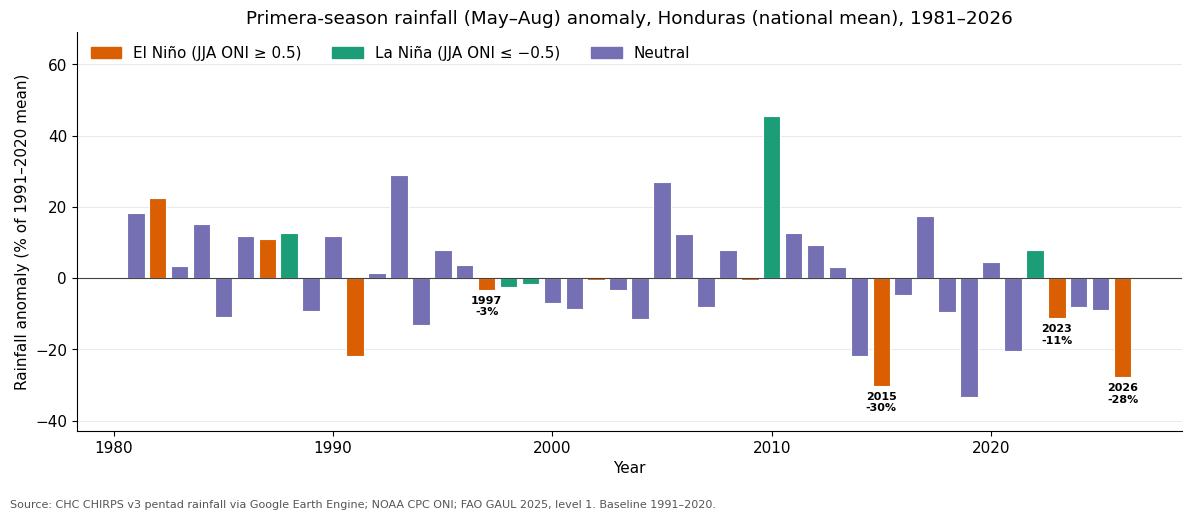

In [11]:

COLORS = {'El Niño': '#d95f02', 'La Niña': '#1b9e77', 'Neutral': '#7570b3', 'Unknown': '#bdbdbd'}
SOURCE = (f'Source: CHC CHIRPS {CHIRPS_VERSION} pentad rainfall via Google Earth Engine; '
          f'NOAA CPC ONI; {BOUNDARY_SOURCE}. Baseline {BASELINE[0]}–{BASELINE[1]}.')
LABEL = 'Dry Corridor departments' if FOCUS == 'DRY_CORRIDOR' else 'Honduras (national mean)'
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})

s = seasonal[seasonal['dept'] == FOCUS].dropna(subset=['primera_mm_anom_pct']).sort_values('year')
fig, ax = plt.subplots(figsize=(12, 5.2))
ax.bar(s['year'], s['primera_mm_anom_pct'], width=0.8,
       color=s['enso_jja'].map(COLORS), edgecolor='white', linewidth=0.8)
ax.axhline(0, color='#444', linewidth=0.8)
for y in EVENT_YEARS:
    row = s[s['year'] == y]
    if len(row):
        v = row['primera_mm_anom_pct'].iloc[0]
        ax.annotate(f'{y}\n{v:+.0f}%', (y, v), xytext=(0, 4 if v >= 0 else -4),
                    textcoords='offset points', ha='center', va='bottom' if v >= 0 else 'top',
                    fontsize=8, fontweight='bold')
handles = [plt.Rectangle((0, 0), 1, 1, color=COLORS[k]) for k in ['El Niño', 'La Niña', 'Neutral']]
ax.legend(handles, ['El Niño (JJA ONI ≥ 0.5)', 'La Niña (JJA ONI ≤ −0.5)', 'Neutral'],
          frameon=False, loc='upper left', ncol=3)
lo, hi = s['primera_mm_anom_pct'].min(), s['primera_mm_anom_pct'].max()
pad = (hi - lo) * 0.12
ax.set_ylim(lo - pad, hi + 2.5 * pad)        # headroom for the legend
ax.set_title(f'Primera-season rainfall (May–Aug) anomaly, {LABEL}, {int(s.year.min())}–{int(s.year.max())}')
ax.set_xlabel('Year')
ax.set_ylabel(f'Rainfall anomaly (% of {BASELINE[0]}–{BASELINE[1]} mean)')
ax.grid(axis='y', color='#e5e5e5', linewidth=0.6)
ax.set_axisbelow(True)
fig.text(0.01, 0.01, SOURCE, fontsize=8, color='#555')
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(f'{OUT_DIR}/fig_rain_timeseries.png', dpi=300)
plt.show()

In [12]:
# Written by: Claude (Anthropic), 25 Oct 2026, chat conversation. Reviewed by: Fabricio Correa Lara
# What I checked: ("18 departments printed, names correct")
# What I changed: (none yet)
import ee, json, time, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

PROJECT_ID = 'enso-honduras'   # <- from step 0.3

ee.Authenticate()                  # opens a sign-in prompt the first time
ee.Initialize(project=PROJECT_ID)
drive.mount('/content/drive')
print('Earth Engine and Drive connected.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Earth Engine and Drive connected.


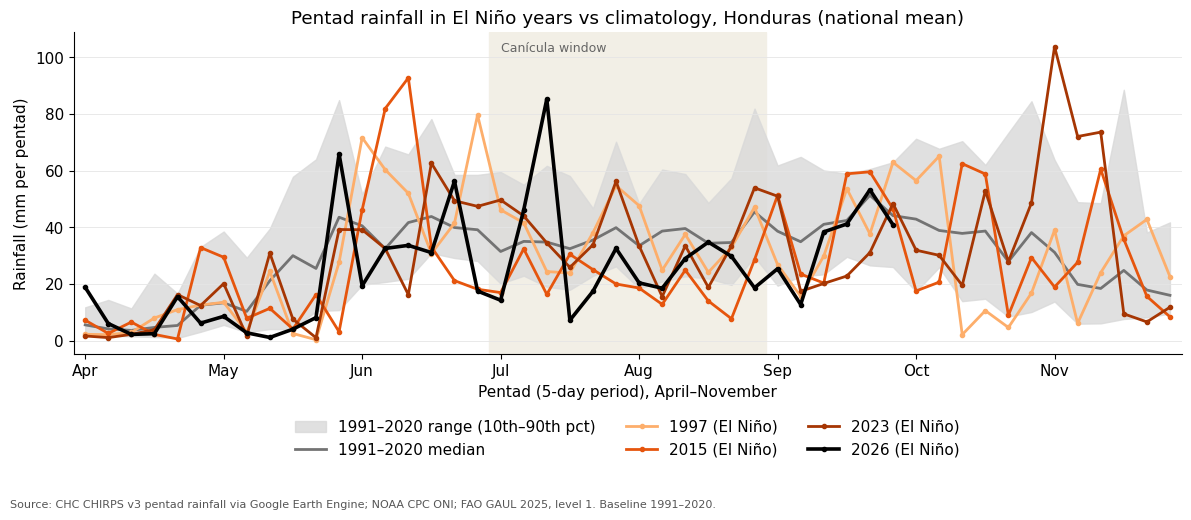

In [13]:

# Pentad-by-pentad rainfall, April-November: where in the season each event went dry
f = df[df['dept'] == FOCUS]
win = f[f['month'].between(4, 11)]
clim = (win[win['year'].between(*BASELINE)].groupby('pentad_of_year')['precip_mm']
          .quantile([0.1, 0.5, 0.9]).unstack())

fig, ax = plt.subplots(figsize=(12, 5.2))
ax.axvspan((CANICULA_MONTHS[0] - 1) * 6 + 0.5, CANICULA_MONTHS[-1] * 6 + 0.5,
           color='#f2efe6', zorder=0)
ax.text((CANICULA_MONTHS[0] - 1) * 6 + 1, 0.97, 'Canícula window', transform=ax.get_xaxis_transform(),
        fontsize=9, color='#666', va='top')
ax.fill_between(clim.index, clim[0.1], clim[0.9], color='#d9d9d9', alpha=0.8,
                label=f'{BASELINE[0]}–{BASELINE[1]} range (10th–90th pct)')
ax.plot(clim.index, clim[0.5], color='#737373', linewidth=2, label=f'{BASELINE[0]}–{BASELINE[1]} median')
line_colors = ['#fdae6b', '#e6550d', '#a63603', '#000000']
for y, c in zip(EVENT_YEARS, line_colors):
    yy = win[win['year'] == y].dropna(subset=['precip_mm'])
    if len(yy):
        lw = 2.6 if y == max(EVENT_YEARS) else 2
        ax.plot(yy['pentad_of_year'], yy['precip_mm'], color=c, linewidth=lw,
                marker='o', markersize=3, label=f'{y} ({enso_class(y)})')
ticks = [(m - 1) * 6 + 1 for m in range(4, 12)]
ax.set_xticks(ticks, ['Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov'])
ax.set_xlim(ticks[0] - 0.5, 66.5)
ax.set_title(f'Pentad rainfall in El Niño years vs climatology, {LABEL}')
ax.set_xlabel('Pentad (5-day period), April–November')
ax.set_ylabel('Rainfall (mm per pentad)')
ax.grid(axis='y', color='#e5e5e5', linewidth=0.6)
ax.legend(frameon=False, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.16))
fig.text(0.01, 0.01, SOURCE, fontsize=8, color='#555')
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(f'{OUT_DIR}/fig_rain_comparison.png', dpi=300)
plt.show()

In [14]:
# Written by: Claude (Anthropic), 25 Oct 2026, chat conversation. Reviewed by: Fabricio Correa Lara
# What I checked: ("18 departments printed, names correct")
# What I changed: (none yet)
import ee, json, time, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

PROJECT_ID = 'enso-honduras'   # <- from step 0.3

ee.Authenticate()                  # opens a sign-in prompt the first time
ee.Initialize(project=PROJECT_ID)
drive.mount('/content/drive')
print('Earth Engine and Drive connected.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Earth Engine and Drive connected.


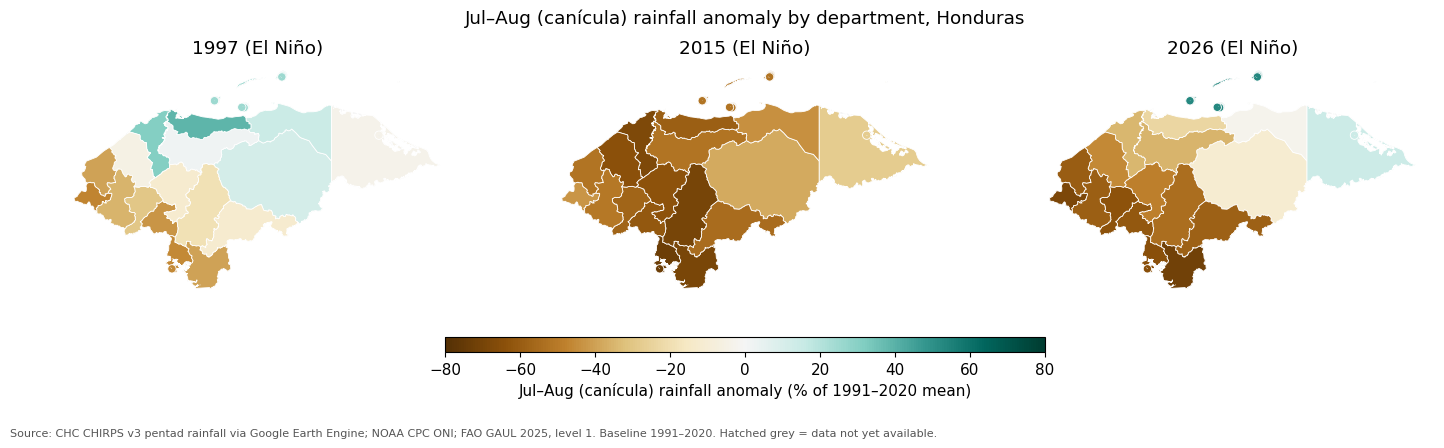

In [15]:

# Map: anomaly by department for each map year
import geopandas as gpd
from matplotlib.colors import TwoSlopeNorm

gdf = gpd.read_file(GEOJSON_PATH)
vals = seasonal[seasonal['year'].isin(MAP_YEARS)][['dept', 'year', MAP_METRIC, 'enso_jja']]
vmax = np.nanmax(np.abs(vals[MAP_METRIC])) if vals[MAP_METRIC].notna().any() else 50
vmax = max(10, np.ceil(vmax / 10) * 10)
norm_ = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

fig, axes = plt.subplots(1, len(MAP_YEARS), figsize=(5 * len(MAP_YEARS), 4.4))
fig.subplots_adjust(left=0.02, right=0.98, top=0.86, bottom=0.32, wspace=0.05)
for ax, y in zip(np.atleast_1d(axes), MAP_YEARS):
    m = gdf.merge(vals[vals['year'] == y], on='dept', how='left')
    m.plot(ax=ax, color='#e0e0e0', edgecolor='white', linewidth=0.6, hatch='///')   # no data
    m.dropna(subset=[MAP_METRIC]).plot(ax=ax, column=MAP_METRIC, cmap='BrBG', norm=norm_,
                                       edgecolor='white', linewidth=0.6)
    ax.set_title(f'{y} ({enso_class(y)})')
    ax.set_axis_off()
sm = plt.cm.ScalarMappable(cmap='BrBG', norm=norm_)
cax = fig.add_axes([0.3, 0.2, 0.4, 0.035])
cbar = fig.colorbar(sm, cax=cax, orientation='horizontal')
window = 'Jul–Aug (canícula)' if MAP_METRIC.startswith('canicula') else 'May–Aug (primera)'
cbar.set_label(f'{window} rainfall anomaly (% of {BASELINE[0]}–{BASELINE[1]} mean)')
fig.suptitle(f'{window} rainfall anomaly by department, Honduras')
fig.text(0.01, 0.01, SOURCE + ' Hatched grey = data not yet available.', fontsize=8, color='#555')
fig.savefig(f'{OUT_DIR}/fig_rain_map.png', dpi=300)
plt.show()

In [16]:
# Written by: Claude (Anthropic), 25 Oct 2026, chat conversation. Reviewed by: Fabricio Correa Lara
# What I checked: ("18 departments printed, names correct")
# What I changed: (none yet)
import ee, json, time, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

PROJECT_ID = 'enso-honduras'   # <- from step 0.3

ee.Authenticate()                  # opens a sign-in prompt the first time
ee.Initialize(project=PROJECT_ID)
drive.mount('/content/drive')
print('Earth Engine and Drive connected.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Earth Engine and Drive connected.


## 9 · Facts for your Milestone 1 data summary
This prints facts only. The one-page summary itself should be written by you.

In [17]:

nat = seasonal[seasonal['dept'] == 'HONDURAS_NATIONAL']
print(f'Dataset: CHIRPS {CHIRPS_VERSION} pentad ({CHIRPS_ID}), 0.05° grid, via Google Earth Engine')
print(f'Coverage: {df.date.min().date()} to {df.date.max().date()}; {df.dept.nunique()} regions; {len(df):,} rows')
print(f'Boundaries: {BOUNDARY_SOURCE}')
print('Years without a complete primera season:', nat.loc[nat['primera_mm'].isna(), 'year'].tolist())
print('Version coverage checked:', coverage)
print(f'Dry-pentad threshold: {DRY_PENTAD_MM} mm; baseline {BASELINE}')

Dataset: CHIRPS v3 pentad (UCSB-CHC/CHIRPS/V3/PENTAD), 0.05° grid, via Google Earth Engine
Coverage: 1981-01-01 to 2026-09-26; 19 regions; 62,586 rows
Boundaries: FAO GAUL 2025, level 1
Years without a complete primera season: []
Version coverage checked: {'v3': ('1981-01-01', '2026-09-26'), 'v2': ('1981-01-01', '2026-09-26')}
Dry-pentad threshold: 10.0 mm; baseline (1991, 2020)


In [18]:
# Written by: Claude (Anthropic), 25 Oct 2026, chat conversation. Reviewed by: Fabricio Correa Lara
# What I checked: ("18 departments printed, names correct")
# What I changed: (none yet)
import ee, json, time, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

PROJECT_ID = 'enso-honduras'   # <- from step 0.3

ee.Authenticate()                  # opens a sign-in prompt the first time
ee.Initialize(project=PROJECT_ID)
drive.mount('/content/drive')
print('Earth Engine and Drive connected.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Earth Engine and Drive connected.


## Notes for your Methods section and data problems
- **Cite the dataset version you used.** v3: *Climate Hazards Center Infrared Precipitation with Stations version 3. CHIRPS3 Data Repository, doi:10.15780/G2JQ0P (2025).* v2: *Funk et al. (2015), Scientific Data 2, 150066, doi:10.1038/sdata.2015.66.* Add the Earth Engine dataset ID and your access date.
- **Department means are area averages.** Rainfall varies a lot inside large departments (e.g. mountains vs valleys); say so.
- **CHIRPS blends satellite estimates with station data;** station density in Honduras affects accuracy, especially for the earliest years. Comparing 1997 with 2026 assumes the record is consistent across that span.
- **The dry-pentad threshold and the season windows are your choices.** Rerun with other values (e.g. 5 and 15 mm; JJA vs Jul–Aug) and report whether the conclusion changes, as you did with JJA vs JAS ONI.
- **If 2026 shows as incomplete,** that is a data problem worth reporting: the final CHIRPS product lags real time.